# Peak-Event Intraday Performance Analysis

**Question:** during a one-day sales peak, which brands will miss their target, by how much, and what should be done in the next hours?

This notebook is the analytical engine behind the interactive dashboard in this repository (`index.html`). It loads the five input tables, cleans and consolidates hourly checkpoints, measures pace against a plan curve, forecasts the close, and applies escalation rules. The calculation logic lives in [`pipeline.py`](pipeline.py); this notebook tells the story and checks the numbers against the dashboard.

Brands and channels are anonymised (Brand A–F, Channel A and B). Revenue is in euros.

## Executive summary

1. **The portfolio beat its target, but one brand did not.** Total GMV closed at **€154.9K against a €115.0K target (134.7%)**; five of six brands finished above plan, while **Brand A ended at 18.6%** of its target.
2. **The shortfall was visible early.** At 12.00 Brand A was at 15.3% pace and needed about **15 times its current hourly run-rate** to catch up. A portfolio total of 115% pace at that hour would have hidden this.
3. **Performance is concentrated.** **Brand E generated about 65% of portfolio GMV**, so portfolio pace mostly tracks one brand.
4. **Conversion differs sharply by brand** (0.85% to 6.44%), and the all-brand benchmark rule flags the weakest funnels.
5. **Data quality needs attention before decisions are automated:** a share of checkpoints carry flags, and some hours are missing for one brand.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pipeline as P

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

BRAND_COLORS = {"Brand A": "#4e79a7", "Brand B": "#f28e2b", "Brand C": "#59a14f",
                "Brand D": "#b07aa1", "Brand E": "#76b7b2", "Brand F": "#9c755f"}
NAVY, AMBER, GREY = "#0A2540", "#D9922B", "#7C8DA6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "axes.titlelocation": "left"})

## 2. Data

Five input tables (`data/`): hourly checkpoints for each channel, targets per brand and channel, the plan curve (expected cumulative share of the day's GMV by hour) and benchmarks from earlier events.

In [2]:
res = P.run(campaign="9.9")          # peak event 9.9, all channels, end of day
tables = res["tables"]

overview = pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in tables.items()}).T
display(overview)
print("Brands:", ", ".join(sorted(tables["targets"]["Brand"].unique())))
print("Peak events with targets:", ", ".join(sorted(tables["targets"]["Campaign"].astype(str).unique())))

Brands: Brand A, Brand B, Brand C, Brand D, Brand E, Brand F
Peak events with targets: 11.11, 9.9


,rows,columns
chA,100,20
chB,98,31
targets,19,6
curve,24,3
benchmarks,10,16


## 3. Data preparation

Two rules matter most:

- **Midnight rule.** A checkpoint captured just after midnight for a session that began the day before is the previous day's closing value (23.59). Without it, every brand would lose its last hour.
- **Sessions add up.** A brand can run several sessions in a day. Each hour takes the latest checkpoint of every session so far and sums them.

In [3]:
snaps = res["snapshots"]
after_midnight = snaps[snaps["at"].str[:10] > "2026-09-09"]
print(f"{len(snaps)} checkpoints kept; {len(after_midnight)} were captured after midnight and count as 23.59 of the peak day.")
after_midnight[["brand", "platform", "at", "hour", "gmv"]].head(8)

198 checkpoints kept; 8 were captured after midnight and count as 23.59 of the peak day.


,brand,platform,at,hour,gmv
23,Brand D,Channel A,2026-09-10 00:01:46,24.0,18646.82
47,Brand E,Channel A,2026-09-10 00:00:00,24.0,65173.68
59,Brand B,Channel A,2026-09-10 00:00:29,24.0,1909.20
75,Brand C,Channel A,2026-09-10 00:01:00,24.0,1947.34
99,Brand F,Channel A,2026-09-10 00:01:17,24.0,10550.31
135,Brand B,Channel B,2026-09-10 00:02:07,24.0,419.27
160,Brand A,Channel B,2026-09-10 00:03:00,24.0,199.20
174,Brand C,Channel B,2026-09-10 00:02:47,24.0,773.66


### Data quality

Checkpoints are extracted from dashboard screenshots, so some carry flags. The dashboard shows these under *Data quality*; here they are counted per brand.

In [4]:
flag_types = {"counter mid-animation": "Counter mid-animation", "off-schedule": "Off-schedule capture",
              "differs from manual report": "Differs from manual report", "blank:": "Blank field"}
parts = [snaps[snaps["flags"].str.contains(key, regex=False)].groupby("brand").size().rename(label)
         for key, label in flag_types.items()]
quality = pd.concat(parts, axis=1).fillna(0).astype(int)
quality["Checkpoints"] = snaps.groupby("brand").size()
quality["Any flag"] = snaps[snaps["flags"].str.contains("|".join(flag_types), regex=True)].groupby("brand").size()
quality = quality.fillna(0).astype(int)
quality["Share flagged"] = (quality["Any flag"] / quality["Checkpoints"]).map("{:.0%}".format)
display(quality)

bh = pd.DataFrame(res["brand_hour"])
gaps = bh[bh["missing"] != ""][["brand", "slot", "missing"]]
print("Hours with a missing checkpoint (last value carried forward):")
display(gaps)

Hours with a missing checkpoint (last value carried forward):


,Counter mid-animation,Off-schedule capture,Differs from manual report,Blank field,Checkpoints,Any flag,Share flagged
brand,,,,,,,
Brand D,1,0,1,1,48,2,4%
Brand E,2,0,1,2,24,3,12%
Brand A,0,1,2,2,25,3,12%
Brand F,0,3,6,1,47,10,21%
Brand C,0,0,2,5,30,7,23%
Brand B,0,0,0,4,24,4,17%


,brand,slot,missing
98,Brand F,03.00,"Channel A, Channel B"
106,Brand F,11.00,Channel B
107,Brand F,12.00,Channel B


## 4. Pace against plan

**Pace = GMV ÷ (target × expected cumulative share at that hour).** A pace of 100% means a brand is exactly where the plan curve says it should be. Status: on track at 100% or above, at risk from 90% to 100%, behind below 90%.

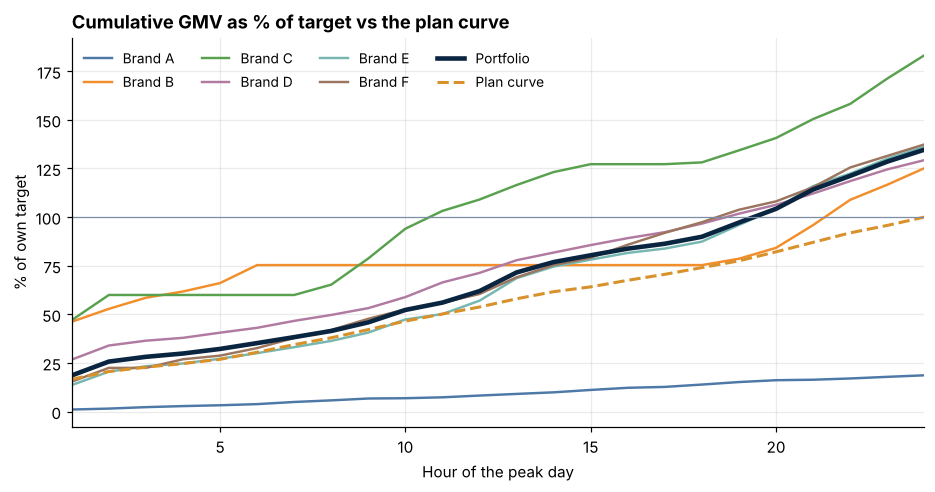

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for brand, g in bh.groupby("brand"):
    ax.plot(g["hour"], g["achieved"] * 100, color=BRAND_COLORS[brand], lw=1.6, label=brand)
port = bh.groupby("hour")[["gmv", "target"]].sum()
ax.plot(port.index, port["gmv"] / port["target"] * 100, color=NAVY, lw=3, label="Portfolio")
plan = bh.groupby("hour")["expected_share"].first() * 100
ax.plot(plan.index, plan.values, ls="--", color=AMBER, lw=2, label="Plan curve")
ax.axhline(100, color=GREY, lw=0.8)
ax.set_xlim(1, 24); ax.set_xlabel("Hour of the peak day"); ax.set_ylabel("% of own target")
ax.set_title("Cumulative GMV as % of target vs the plan curve")
ax.legend(ncol=4, loc="upper left", frameon=False, fontsize=9)
plt.show()

### Brand scorecard at the end of the day

In [6]:
def scorecard(bs):
    rows = sorted(bs, key=lambda r: r["pace"])
    return pd.DataFrame([{
        "Brand": r["brand"], "GMV": P.eur(r["gmv"]), "Target": P.eur(r["target"]),
        "Achieved": P.pct(r["achieved"]), "Pace": P.pct(r["pace"]), "Status": r["status"],
        "Variance": P.eur(r["gap"]), "Required /h": P.eur(r["need_per_hour"]), "Current /h": P.eur(r["rate3"]),
        "Forecast (curve)": P.eur(r["rr_curve"]), "Conversion": P.pct(r["cr"]), "Views": f"{r['views']:,.0f}",
    } for r in rows]).set_index("Brand")

bs = res["brand_status"]
kpi = res["kpi"]
print(f"Portfolio at {P.slot_label(kpi['hour'])}: {P.eur(kpi['gmv'])} of {P.eur(kpi['target'])} "
      f"({P.pct(kpi['achieved'])}), status: {kpi['status']}")
scorecard(bs)

Portfolio at 23.59: €154.9K of €115.0K (134.7%), status: On track


,GMV,Target,Achieved,Pace,Status,Variance,Required /h,Current /h,Forecast (curve),Conversion,Views
Brand,,,,,,,,,,,
Brand A,€358,€1.9K,18.6%,18.6%,Behind,€1.6K,—,€15,€358,2.13%,"9,590"
Brand B,€5.8K,€4.7K,125.1%,125.1%,On track,€0,—,€456,€5.8K,4.07%,"14,098"
Brand D,€25.9K,€20.0K,129.3%,129.3%,On track,€0,—,€1.1K,€25.9K,2.79%,"100,941"
Brand E,€99.9K,€73.4K,136.2%,136.2%,On track,€0,—,€5.0K,€99.9K,1.25%,"57,836"
Brand F,€13.9K,€10.1K,137.4%,137.4%,On track,€0,—,€741,€13.9K,0.85%,"133,982"
Brand C,€8.9K,€4.9K,183.2%,183.2%,On track,€0,—,€531,€8.9K,6.44%,"16,488"


## 5. Replaying the day: what was visible at 12.00?

Forecasts are only useful while there is still time to act. Replaying the same analysis at 12.00 shows the position when interventions were still possible.

In [7]:
bs12 = P.build_brand_status(res["brand_hour"], tables["benchmarks"], asof=12)
kpi12 = P.build_cluster_kpi(bs12)
print(f"Portfolio at 12.00: {P.eur(kpi12['gmv'])} of {P.eur(kpi12['target'])} target; pace {P.pct(kpi12['pace'])}; "
      f"required {P.eur(kpi12['need_per_hour'])}/h vs current {P.eur(kpi12['rate3'])}/h")
scorecard(bs12)

Portfolio at 12.00: €71.2K of €115.0K target; pace 115.2%; required €3.6K/h vs current €6.2K/h


,GMV,Target,Achieved,Pace,Status,Variance,Required /h,Current /h,Forecast (curve),Conversion,Views
Brand,,,,,,,,,,,
Brand A,€158,€1.9K,8.24%,15.3%,Behind,€1.8K,€147,€10,€294,—,"4,450"
Brand E,€41.9K,€73.4K,57.0%,106.1%,On track,€31.5K,€2.6K,€4.0K,€77.8K,0.96%,"26,728"
Brand F,€6.1K,€10.1K,60.5%,112.4%,On track,€4.0K,€334,€430,€11.4K,1.03%,"54,819"
Brand D,€14.3K,€20.0K,71.3%,132.6%,On track,€5.8K,€479,€1.2K,€26.6K,3.14%,"49,069"
Brand B,€3.5K,€4.7K,75.3%,140.1%,On track,€1.2K,€96,€0,€6.5K,4.71%,"6,751"
Brand C,€5.3K,€4.9K,109.0%,202.8%,On track,€0,€0,€491,€9.9K,8.10%,"8,035"


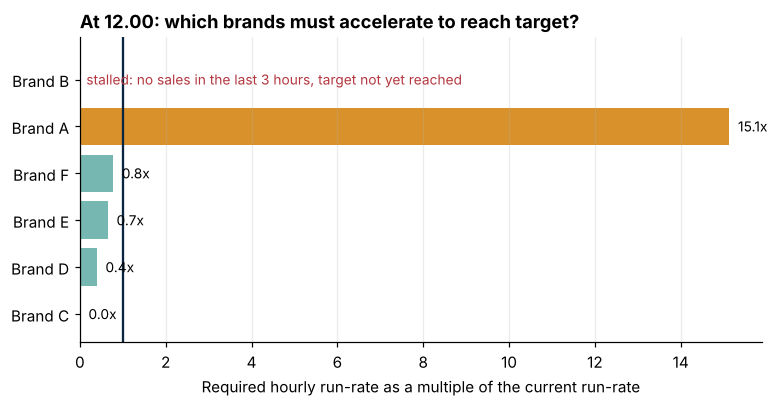

In [8]:
need = pd.Series({r["brand"]: r["need_per_hour"] or 0 for r in bs12})
now = pd.Series({r["brand"]: r["rate3"] for r in bs12})
ratio = (need / now.where(now > 0)).sort_values()          # NaN where the brand sold nothing in the last 3 hours
stalled = now[(now <= 0) & (need > 0)].index
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, brand in enumerate(ratio.index):
    v = ratio[brand]
    if brand in stalled:
        ax.text(0.15, i, "stalled: no sales in the last 3 hours, target not yet reached", va="center", fontsize=9, color="#B3363F")
    else:
        ax.barh(brand, v, color=AMBER if v > 1 else "#76b7b2")
        ax.text(v + 0.2, i, f"{v:.1f}x", va="center", fontsize=9)
ax.set_yticks(range(len(ratio))); ax.set_yticklabels(ratio.index)
ax.axvline(1, color=NAVY, lw=1.5)
ax.set_ylim(-0.6, len(ratio) - 0.1)
ax.set_xlabel("Required hourly run-rate as a multiple of the current run-rate")
ax.set_title("At 12.00: which brands must accelerate to reach target?")
ax.grid(axis="y", visible=False)
plt.show()

## 6. Funnel diagnostics

A metric is flagged when it is at least 20% below a benchmark (the brand's own day average, or the all-brand average for rates). Conversion (orders ÷ views) is the clearest example.

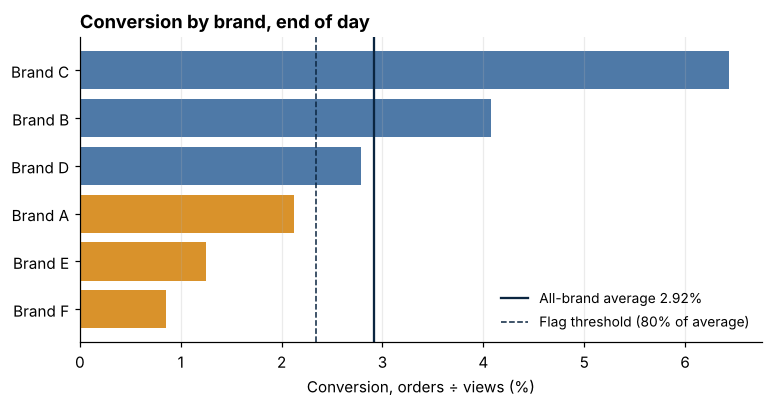

In [9]:
conv = pd.Series({r["brand"]: r["cr"] for r in bs if r["cr"] is not None}).sort_values()
avg_cr = conv.mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(conv.index, conv.values * 100, color=[AMBER if v < avg_cr * P.LOW else "#4e79a7" for v in conv])
ax.axvline(avg_cr * 100, color=NAVY, lw=1.5, label=f"All-brand average {avg_cr:.2%}")
ax.axvline(avg_cr * P.LOW * 100, color=NAVY, lw=1, ls="--", label="Flag threshold (80% of average)")
ax.set_xlabel("Conversion, orders ÷ views (%)")
ax.set_title("Conversion by brand, end of day")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

## 7. Concentration risk

How much of the portfolio result depends on a single brand?

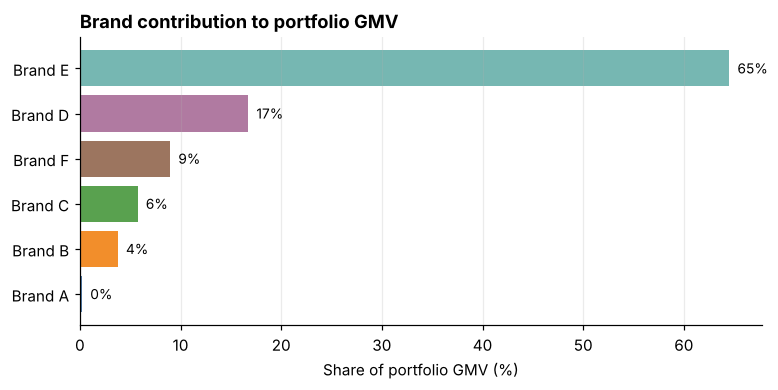

In [10]:
share = pd.Series({r["brand"]: r["gmv"] for r in bs})
share = (share / share.sum()).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(share.index, share.values * 100, color=[BRAND_COLORS[b] for b in share.index])
for i, v in enumerate(share.values):
    ax.text(v * 100 + 0.8, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlabel("Share of portfolio GMV (%)")
ax.set_title("Brand contribution to portfolio GMV")
ax.grid(axis="y", visible=False)
plt.show()

## 8. Interventions

Every hour the rules produce a list of interventions: behind plan or at risk, funnel flags, paid-media issues and missing data. The chart counts the flags raised at each hour (excluding "on track").

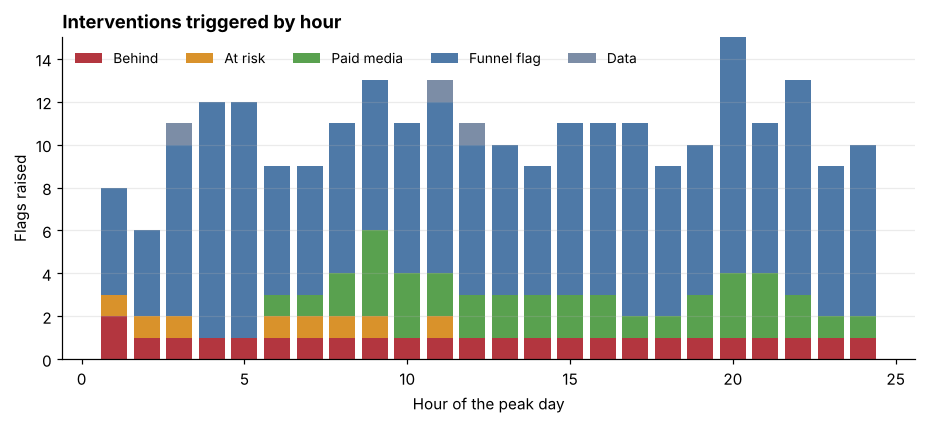

In [11]:
act = pd.DataFrame(res["actions"])
flags = act[act["kind"] != "On track"].pivot_table(index="hour", columns="kind", values="brand", aggfunc="count").fillna(0)
order = [k for k in ["Behind", "At risk", "Paid media", "Funnel flag", "Data"] if k in flags.columns]
palette = {"Behind": "#B3363F", "At risk": AMBER, "Paid media": "#59a14f", "Funnel flag": "#4e79a7", "Data": GREY}
fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(flags))
for k in order:
    ax.bar(flags.index, flags[k], bottom=bottom, color=palette[k], label=k)
    bottom += flags[k].values
ax.set_xlabel("Hour of the peak day"); ax.set_ylabel("Flags raised")
ax.set_title("Interventions triggered by hour")
ax.legend(ncol=5, frameon=False, fontsize=9, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

In [12]:
at12 = act[(act["hour"] == 12) & (act["kind"] != "On track")][["brand", "kind", "text"]]
print("Interventions at 12.00")
display(at12.reset_index(drop=True))

Interventions at 12.00


,brand,kind,text
0,Brand A,Behind,▼ pace 15.3% · 8.24% of target · variance €1.8K · required €147/h vs €10/h current
1,Brand B,Funnel flag,comments ▼ 32.7/1k views (all brands 43.5)
2,Brand D,Funnel flag,conversion ▼ 1.94% last hour (day 3.23%)
3,Brand E,Funnel flag,conversion ▼ 0.96% (all brands 3.59%)
4,Brand F,Funnel flag,conversion ▼ 1.03% (all brands 3.59%)
5,Brand F,Funnel flag,"views ▼ 3,596/h (avg 4,657/h)"
6,Brand F,Funnel flag,comments ▼ 26.6/1k views (all brands 43.5)
7,Brand C,Funnel flag,conversion ▼ 4.61% last hour (day 8.41%)
8,Brand D,Paid media,ROI ▼ 113.7 (3h ago 179.6) · spend €33
9,Brand C,Paid media,paid boost switched off


## 9. Reconciliation with the dashboard

The dashboard and this notebook implement the same rules independently. These checks compare the portfolio figures and the number of brands per intervention box with what the dashboard shows. (A full comparison of all 144 hourly brand rows and all 366 intervention messages was identical when this notebook was built.)

In [13]:
def kinds(h):
    s = act[act["hour"] == h].groupby("kind")["brand"].nunique()
    return {k: int(s.get(k, 0)) for k in ["On track", "Behind", "At risk", "Paid media", "Funnel flag"]}

checks = {
    "Portfolio GMV at 23.59 (EUR K)": (round(kpi["gmv"] / 1e3, 1), 154.9),
    "Portfolio target (EUR K)": (round(kpi["target"] / 1e3, 1), 115.0),
    "Share of target (%)": (round(kpi["achieved"] * 100, 1), 134.7),
    "Orders": (int(kpi["orders"]), 4879),
    "Conversion (%)": (round(kpi["cr"] * 100, 2), 1.73),
    "Pace at 12.00 (%)": (round(kpi12["pace"] * 100, 1), 115.2),
    "Variance at 12.00 (EUR K)": (round(kpi12["gap"] / 1e3, 1), 43.8),
    "Brands per box at 23.59": (kinds(24), {"On track": 5, "Behind": 1, "At risk": 0, "Paid media": 1, "Funnel flag": 4}),
    "Brands per box at 12.00": (kinds(12), {"On track": 5, "Behind": 1, "At risk": 0, "Paid media": 2, "Funnel flag": 5}),
}
table = pd.DataFrame([{"Check": k, "Notebook": str(a), "Dashboard": str(b), "Match": "yes" if a == b else "NO"}
                      for k, (a, b) in checks.items()])
assert all(a == b for a, b in checks.values()), "Reconciliation failed"
display(table)

,Check,Notebook,Dashboard,Match
0,Portfolio GMV at 23.59 (EUR K),154.9,154.9,yes
1,Portfolio target (EUR K),115.0,115.0,yes
2,Share of target (%),134.7,134.7,yes
3,Orders,4879,4879,yes
4,Conversion (%),1.73,1.73,yes
5,Pace at 12.00 (%),115.2,115.2,yes
6,Variance at 12.00 (EUR K),43.8,43.8,yes
7,Brands per box at 23.59,"{'On track': 5, 'Behind': 1, 'At risk': 0, 'Paid media': 1, 'Funnel flag': 4}","{'On track': 5, 'Behind': 1, 'At risk': 0, 'Paid media': 1, 'Funnel flag': 4}",yes
8,Brands per box at 12.00,"{'On track': 5, 'Behind': 1, 'At risk': 0, 'Paid media': 2, 'Funnel flag': 5}","{'On track': 5, 'Behind': 1, 'At risk': 0, 'Paid media': 2, 'Funnel flag': 5}",yes


## 10. Export

The results are written to `python/output/` as CSV and JSON for use in other tools.

In [14]:
P.export(res)
sorted(p.name for p in P.OUT_DIR.iterdir())

['brand_hour.csv', 'brand_scorecard.csv', 'interventions.csv', 'portfolio_kpi.json']

## 11. So what

- **Watch brands, not just the portfolio.** The portfolio was ahead of plan all day while Brand A was far behind. Brand-level pace and the required-versus-current run-rate surface this at 12.00, early enough to react.
- **Treat concentration as a risk.** When one brand carries roughly two thirds of GMV, portfolio pace says little about the rest of the range.
- **Fix the funnel where traffic exists.** Low conversion on high-view brands is the largest lever; the benchmark rule points to where to look first.
- **Improve the data before automating decisions.** Flagged and missing checkpoints are common enough to justify a validation step.

### Next steps

1. Replace the single reference curve with brand-specific plan curves, and test whether they sharpen the pace signal.
2. Add a forecasting model for the close (for example a regression on the intraday share curve) and compare it with the curve and linear forecasts.
3. Calibrate the 20% threshold statistically instead of fixing it by rule.
4. Run the pipeline on further peak events to track forecast accuracy over time.